# Document Image Classification — Exploratory Data Analysis


# 1. Persiapan Lingkungan dan Dataset


## 1.1. Menyiapkan Struktur Direktori Proyek


In [1]:
from pathlib import Path

# Lokasi project
PROJECT_DIR = Path("/kaggle/working/document-classification")

# Daftar folder
folders = [
    "notebooks",
    "src",
    "data",
    "checkpoint",
    "outputs/figures",
    "outputs/predictions",
]

# Membuat folder
for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

# Membuat file awal
files = [
    "src/__init__.py",
    "src/dataset.py",
    "src/model.py",
    "src/train.py",
    "src/evaluate.py",
    "src/predict.py",
    "README.md",
    "requirements.txt",
    ".gitignore",
]

for filename in files:
    path = PROJECT_DIR / filename
    path.touch(exist_ok=True)

print("Project berhasil dibuat!")
print("Lokasi:", PROJECT_DIR)

# Menampilkan struktur
for path in sorted(PROJECT_DIR.rglob("*")):
    relative = path.relative_to(PROJECT_DIR)
    print(
        ("[DIR] " if path.is_dir() else "[FILE] ") +
        str(relative)
    )


Project berhasil dibuat!
Lokasi: /kaggle/working/document-classification
[FILE] .gitignore
[FILE] README.md
[DIR] checkpoint
[DIR] data
[DIR] notebooks
[DIR] outputs
[DIR] outputs/figures
[DIR] outputs/predictions
[FILE] requirements.txt
[DIR] src
[FILE] src/__init__.py
[FILE] src/dataset.py
[FILE] src/evaluate.py
[FILE] src/model.py
[FILE] src/predict.py
[FILE] src/train.py


## 1.2. Konfigurasi Git dan Pengecualian Berkas


In [2]:
gitignore_content = """
# Dataset besar
data/
*.tif
*.tiff
*.zip

# Model checkpoint
checkpoint/
checkpoints/
*.pth
*.pt
*.ckpt

# Cache Python
__pycache__/
*.pyc
.ipynb_checkpoints/

# Environment
.env
.venv/

# Prediksi sementara
outputs/predictions/
"""

(PROJECT_DIR / ".gitignore").write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print(".gitignore berhasil dibuat!")
print((PROJECT_DIR / ".gitignore").read_text())


.gitignore berhasil dibuat!
# Dataset besar
data/
*.tif
*.tiff
*.zip

# Model checkpoint
checkpoint/
checkpoints/
*.pth
*.pt
*.ckpt

# Cache Python
__pycache__/
*.pyc
.ipynb_checkpoints/

# Environment
.env
.venv/

# Prediksi sementara
outputs/predictions/



## 1.3. Verifikasi Lokasi Dataset


In [3]:
# Memastikan Dataset Tetap Terhubung


DATA_DIR = Path(
    "/kaggle/input/competitions/"
    "document-image-classification-sd234504"
)

required_files = [
    "train.csv",
    "test.csv",
    "sample_submission.csv"
]

print("Memeriksa dataset...\n")

for name in required_files:
    path = DATA_DIR / name
    print(
        name,
        "Ada" if path.exists() else "Tidak ditemukan"
    )

print("\nContoh folder gambar:")

train_folder = DATA_DIR / "train" / "train"
test_folder = DATA_DIR / "test" / "test"

print("Training folder:", train_folder.exists())
print("Testing folder :", test_folder.exists())


Memeriksa dataset...

train.csv Ada
test.csv Ada
sample_submission.csv Ada

Contoh folder gambar:
Training folder: True
Testing folder : True


## 1.4. Pemeriksaan Lingkungan dan Ringkasan Dataset


In [4]:
# Mengecek GPU & Dataset

import torch
import pandas as pd
from pathlib import Path

# Lokasi dataset kompetisi
DATA_DIR = Path(
    "/kaggle/input/competitions/"
    "document-image-classification-sd234504"
)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("=" * 50)
print("DATASET & GPU CHECK")
print("=" * 50)

print("Training images:", len(train_df))
print("Testing images :", len(test_df))
print("Total classes  :", train_df["label"].nunique())

print("\nPyTorch version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Status: GPU READY")
else:
    print("GPU belum aktif (CPU mode).")

print("\nDataset preview:")
display(train_df.head())


DATASET & GPU CHECK
Training images: 32003
Testing images : 7994
Total classes  : 16

PyTorch version: 2.11.0+cu128
GPU: Tesla T4
Status: GPU READY

Dataset preview:


,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15


# 2. Exploratory Data Analysis (EDA)


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from IPython.display import display

# Konfigurasi
SEED = 42
DATA_DIR = Path(
    "/kaggle/input/competitions/"
    "document-image-classification-sd234504"
)

# Membaca metadata
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_df = pd.read_csv(
    DATA_DIR / "sample_submission.csv"
)

sns.set_theme(style="whitegrid")

print("=" * 55)
print("DOCUMENT IMAGE CLASSIFICATION - EDA")
print("=" * 55)

print("Jumlah training :", len(train_df))
print("Jumlah testing  :", len(test_df))
print("Jumlah kelas    :", train_df["label"].nunique())

print("\nStruktur train.csv:")
train_df.info()

print("\nContoh training:")
display(train_df.head())

print("\nContoh testing:")
display(test_df.head())


DOCUMENT IMAGE CLASSIFICATION - EDA
Jumlah training : 32003
Jumlah testing  : 7994
Jumlah kelas    : 16

Struktur train.csv:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32003 entries, 0 to 32002
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          32003 non-null  object
 1   filename    32003 non-null  object
 2   class_name  32003 non-null  object
 3   label       32003 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 1000.2+ KB

Contoh training:


,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15



Contoh testing:


,id,filename
0,test_00001,test/test_00001.tif
1,test_00002,test/test_00002.tif
2,test_00003,test/test_00003.tif
3,test_00004,test/test_00004.tif
4,test_00005,test/test_00005.tif


### 2.1. Pemeriksaan Kualitas Data


In [6]:
print("=" * 55)
print("DATA QUALITY ASSESSMENT")
print("=" * 55)

print("\nMissing values training:")
display(train_df.isnull().sum().to_frame("missing"))

print("\nMissing values testing:")
display(test_df.isnull().sum().to_frame("missing"))

print("\nDuplikasi ID:")
print("Train:", train_df["id"].duplicated().sum())
print("Test :", test_df["id"].duplicated().sum())

print("\nDuplikasi filename:")
print("Train:", train_df["filename"].duplicated().sum())
print("Test :", test_df["filename"].duplicated().sum())

# Memastikan setiap label hanya punya satu nama kelas
label_mapping = (
    train_df[["label", "class_name"]]
    .drop_duplicates()
    .sort_values("label")
)

print("\nMapping label:")
display(label_mapping)

print("\nJumlah pasangan label-kategori:",
      len(label_mapping))

assert train_df["label"].isin(range(16)).all()
assert len(label_mapping) == 16

assert (
    label_mapping.groupby("label")["class_name"]
    .nunique().max() == 1
)

assert (
    label_mapping.groupby("class_name")["label"]
    .nunique().max() == 1
)

print("\nPemeriksaan mapping label berhasil.")


DATA QUALITY ASSESSMENT

Missing values training:


,missing
id,0
filename,0
class_name,0
label,0



Missing values testing:


,missing
id,0
filename,0



Duplikasi ID:
Train: 0
Test : 0

Duplikasi filename:
Train: 0
Test : 0

Mapping label:


,label,class_name
12,0,advertisement
11,1,budget
7,2,email
5,3,file_folder
81,4,form
8,5,handwritten
40,6,invoice
6,7,letter
13,8,memo
15,9,news_article



Jumlah pasangan label-kategori: 16

Pemeriksaan mapping label berhasil.


### 2.2. Analisis Distribusi Kelas


,label,class_name,count,percentage
0,0,advertisement,2012,6.286911
1,1,budget,2004,6.261913
2,2,email,2013,6.290035
3,3,file_folder,2022,6.318158
4,4,form,2005,6.265038
5,5,handwritten,2026,6.330657
6,6,invoice,1982,6.193169
7,7,letter,1972,6.161922
8,8,memo,1994,6.230666
9,9,news_article,1971,6.158798


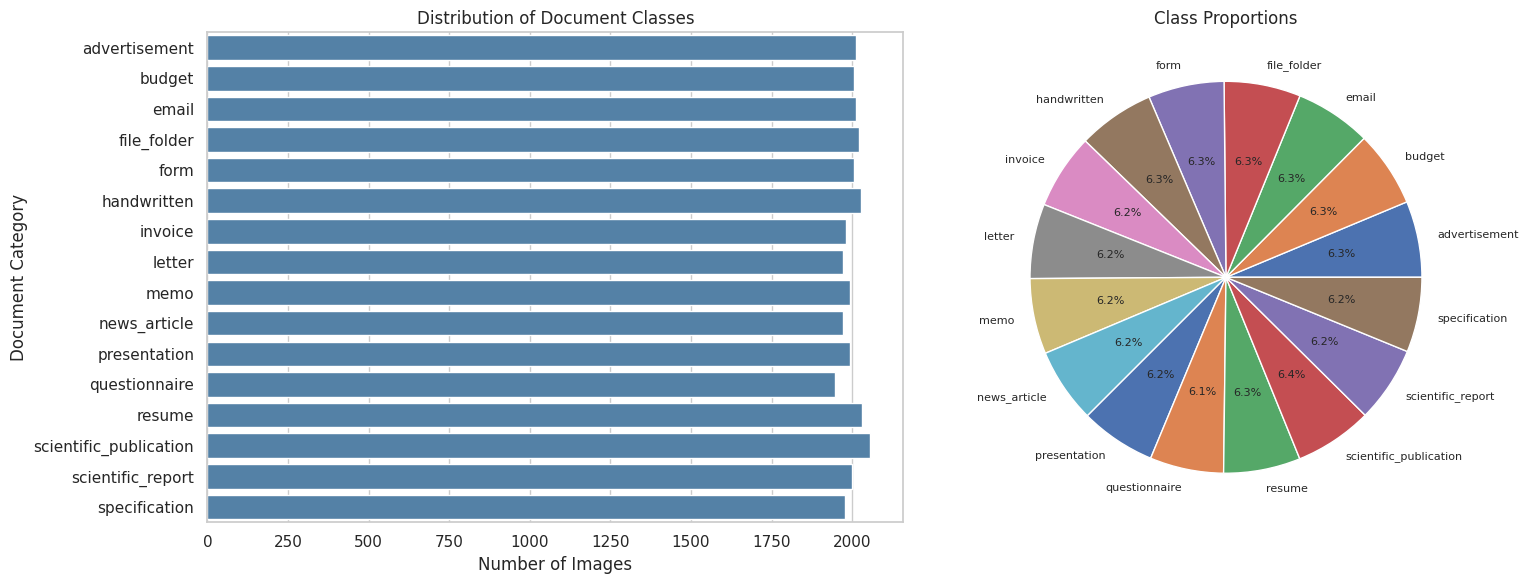

Minimum class samples: 1948
Maximum class samples: 2056
Imbalance ratio: 1.06x


In [7]:
class_dist = (
    train_df.groupby(["label", "class_name"])
    .size()
    .reset_index(name="count")
    .sort_values("label")
)

class_dist["percentage"] = (
    class_dist["count"] / len(train_df) * 100
)

display(class_dist)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=class_dist,
    x="count",
    y="class_name",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution of Document Classes")
axes[0].set_xlabel("Number of Images")
axes[0].set_ylabel("Document Category")

axes[1].pie(
    class_dist["count"],
    labels=class_dist["class_name"],
    autopct="%1.1f%%",
    textprops={"fontsize": 8}
)

axes[1].set_title("Class Proportions")

plt.tight_layout()
plt.show()

# Mengukur ketidakseimbangan kelas
max_count = class_dist["count"].max()
min_count = class_dist["count"].min()

imbalance_ratio = max_count / min_count

print(f"Minimum class samples: {min_count}")
print(f"Maximum class samples: {max_count}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}x")


### 2.3. Visualisasi Contoh Gambar Dokumen


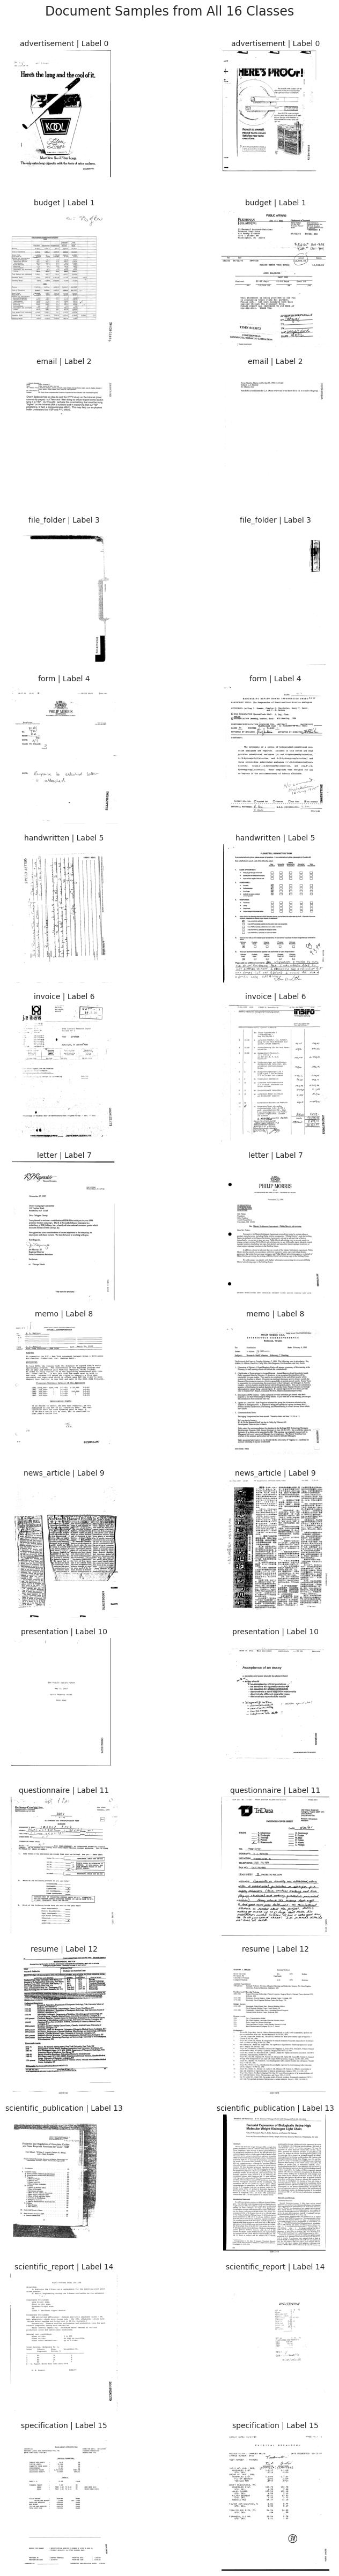

In [8]:
from PIL import Image

def resolve_image_path(filename, split="train"):
    """
    Menentukan lokasi file TIFF berdasarkan metadata CSV.

    Args:
        filename (str): Path relatif gambar.
        split (str): 'train' atau 'test'.

    Returns:
        pathlib.Path: Path gambar yang ditemukan.

    Raises:
        FileNotFoundError: Jika gambar tidak ditemukan.
    """
    filename = str(filename).replace("\\", "/").lstrip("./")
    base = DATA_DIR / split

    candidates = [
        DATA_DIR / filename,
        base / filename,
        base / split / Path(filename).name,
        base / Path(filename).name,
    ]

    for path in candidates:
        if path.is_file():
            return path

    raise FileNotFoundError(filename)


def read_document_image(filename, split="train"):
    """
    Membaca gambar dokumen TIFF dalam format RGB.

    Args:
        filename (str): Path relatif gambar.
        split (str): Jenis dataset.

    Returns:
        PIL.Image.Image: Gambar RGB.
    """
    path = resolve_image_path(filename, split)

    with Image.open(path) as img:
        return img.convert("RGB")


classes = (
    train_df[["label", "class_name"]]
    .drop_duplicates()
    .sort_values("label")
)

fig, axes = plt.subplots(
    16, 2, figsize=(10, 48)
)

for row_idx, (_, row) in enumerate(classes.iterrows()):
    label = row["label"]

    samples = train_df[
        train_df["label"] == label
    ].sample(n=2, random_state=SEED)

    for col_idx, (_, sample) in enumerate(
        samples.iterrows()
    ):
        img = read_document_image(
            sample["filename"]
        )

        axes[row_idx, col_idx].imshow(img)
        axes[row_idx, col_idx].set_title(
            f'{row["class_name"]} | Label {label}',
            fontsize=10
        )
        axes[row_idx, col_idx].axis("off")

plt.suptitle(
    "Document Samples from All 16 Classes",
    fontsize=17,
    y=1.001
)
plt.tight_layout()
plt.show()


### 2.4. Analisis Resolusi dan Rasio Aspek Gambar


Analyzing image dimensions:   0%|          | 0/1600 [00:00<?, ?it/s]

Statistik resolusi:


,width,height,aspect_ratio
count,1600.000000,1600.0,1600.000000
mean,766.428750,1000.0,0.766429
std,21.719197,0.0,0.021719
min,611.000000,1000.0,0.611000
25%,754.000000,1000.0,0.754000
50%,762.000000,1000.0,0.762000
75%,777.000000,1000.0,0.777000
max,1015.000000,1000.0,1.015000



Distribusi orientasi:


,percentage
orientation,
Portrait,99.94
Landscape,0.06


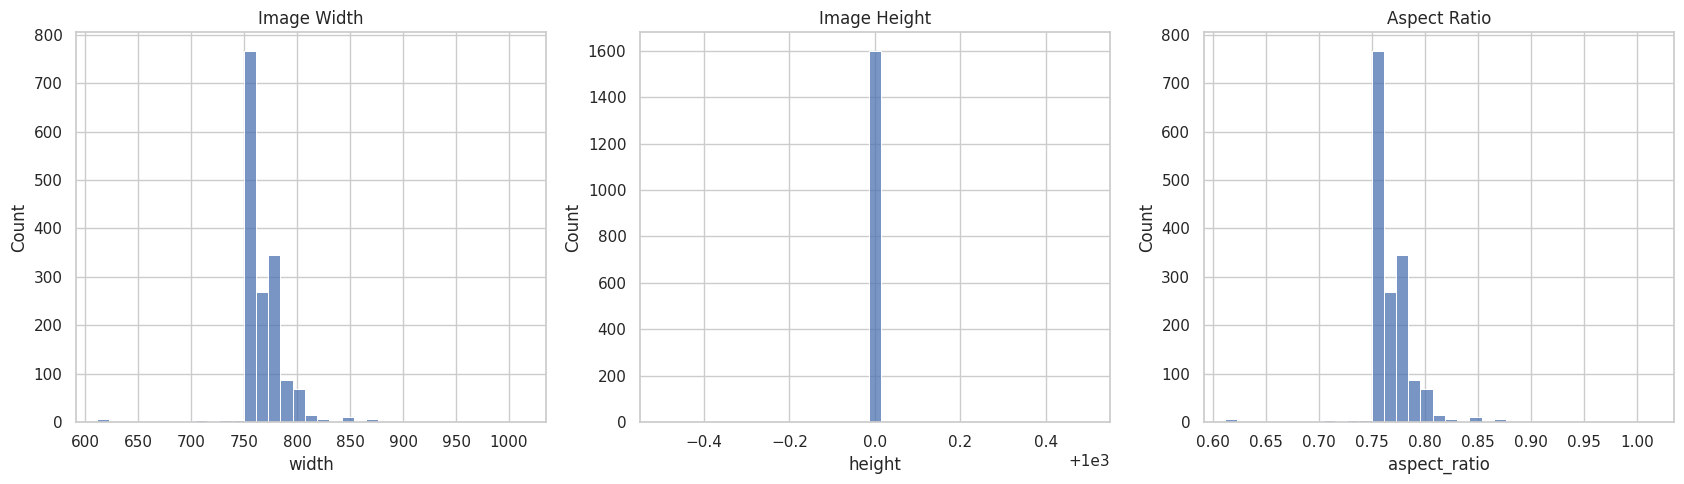

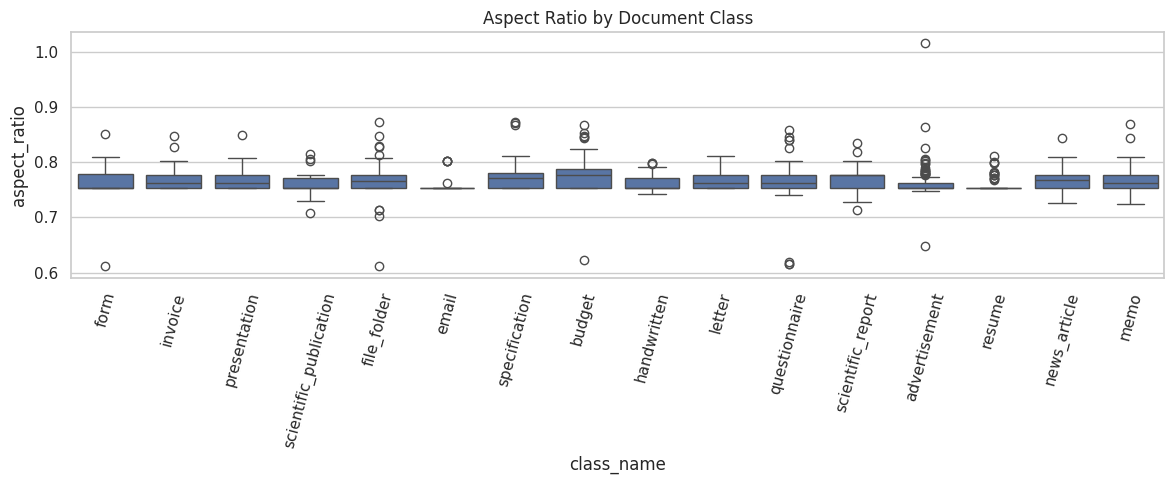

In [9]:
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

# Sampel proporsional dari 16 kelas
eda_sample, _ = train_test_split(
    train_df,
    train_size=1600,
    stratify=train_df["label"],
    random_state=SEED
)

image_stats = []

for _, row in tqdm(
    eda_sample.iterrows(),
    total=len(eda_sample),
    desc="Analyzing image dimensions"
):
    path = resolve_image_path(row["filename"])

    with Image.open(path) as img:
        width, height = img.size

    aspect_ratio = width / height

    if width < height:
        orientation = "Portrait"
    elif width > height:
        orientation = "Landscape"
    else:
        orientation = "Square"

    image_stats.append({
        "id": row["id"],
        "class_name": row["class_name"],
        "width": width,
        "height": height,
        "aspect_ratio": aspect_ratio,
        "orientation": orientation,
    })

stats_df = pd.DataFrame(image_stats)

print("Statistik resolusi:")
display(
    stats_df[
        ["width", "height", "aspect_ratio"]
    ].describe()
)

print("\nDistribusi orientasi:")
display(
    stats_df["orientation"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("percentage")
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.histplot(
    stats_df["width"],
    bins=35,
    ax=axes[0]
)
axes[0].set_title("Image Width")

sns.histplot(
    stats_df["height"],
    bins=35,
    ax=axes[1]
)
axes[1].set_title("Image Height")

sns.histplot(
    stats_df["aspect_ratio"],
    bins=35,
    ax=axes[2]
)
axes[2].set_title("Aspect Ratio")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
sns.boxplot(
    data=stats_df,
    x="class_name",
    y="aspect_ratio"
)
plt.xticks(rotation=75)
plt.title("Aspect Ratio by Document Class")
plt.tight_layout()
plt.show()


### 2.5. Analisis Karakteristik Kualitas Gambar


Analyzing image quality:   0%|          | 0/1600 [00:00<?, ?it/s]

,brightness,contrast,dark_pixel_ratio
count,1600.000000,1600.000000,1600.000000
mean,233.584768,39.623750,0.059199
std,29.143525,23.322075,0.119076
min,22.555058,3.676218,0.000000
25%,232.499592,24.865251,0.006983
50%,242.052750,33.683731,0.019451
75%,247.701252,46.082261,0.051134
max,254.813049,126.302132,0.910739


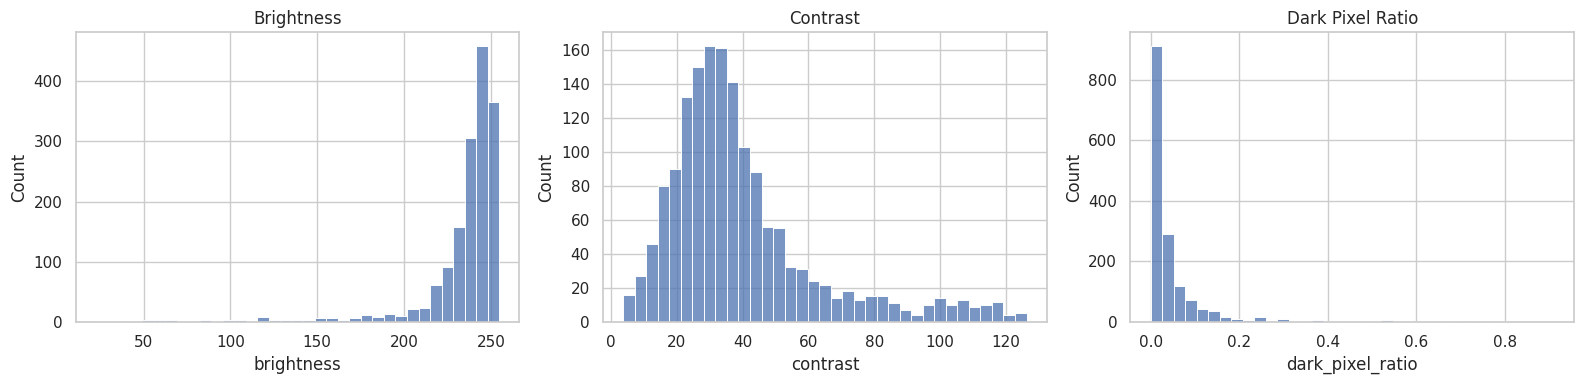

Rata-rata metrik berdasarkan kategori:


,brightness,contrast,dark_pixel_ratio
class_name,,,
advertisement,189.257,77.543,0.243
budget,239.027,32.948,0.040
email,249.190,20.150,0.008
file_folder,208.947,51.326,0.177
form,240.147,35.698,0.030
handwritten,232.904,44.711,0.063
invoice,239.673,37.136,0.036
letter,242.170,34.668,0.029
memo,242.093,33.383,0.027


In [10]:
def calculate_image_quality(filename, split="train"):
    """
    Menghitung karakteristik intensitas visual gambar.

    Args:
        filename (str): Path relatif gambar TIFF.
        split (str): 'train' atau 'test'.

    Returns:
        dict: Kecerahan, kontras, dan dark pixel ratio.
    """
    path = resolve_image_path(filename, split)

    with Image.open(path) as img:
        gray = img.convert("L")
        gray.thumbnail((256, 256))
        pixels = np.asarray(gray, dtype=np.float32)

    brightness = float(pixels.mean())
    contrast = float(pixels.std())
    dark_ratio = float((pixels < 128).mean())

    return {
        "brightness": brightness,
        "contrast": contrast,
        "dark_pixel_ratio": dark_ratio,
    }


quality_records = []

for _, row in tqdm(
    eda_sample.iterrows(),
    total=len(eda_sample),
    desc="Analyzing image quality"
):
    metrics = calculate_image_quality(
        row["filename"]
    )

    quality_records.append({
        "id": row["id"],
        "class_name": row["class_name"],
        **metrics
    })

quality_df = pd.DataFrame(quality_records)

display(
    quality_df[
        ["brightness", "contrast", "dark_pixel_ratio"]
    ].describe()
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(
    axes,
    ["brightness", "contrast", "dark_pixel_ratio"]
):
    sns.histplot(
        quality_df[column],
        bins=35,
        ax=ax
    )
    ax.set_title(column.replace("_", " ").title())

plt.tight_layout()
plt.show()

print("Rata-rata metrik berdasarkan kategori:")
display(
    quality_df.groupby("class_name")[
        ["brightness", "contrast", "dark_pixel_ratio"]
    ].mean().round(3)
)


### 2.6. Perbandingan Karakteristik Data Training dan Testing


Analyzing test images:   0%|          | 0/800 [00:00<?, ?it/s]

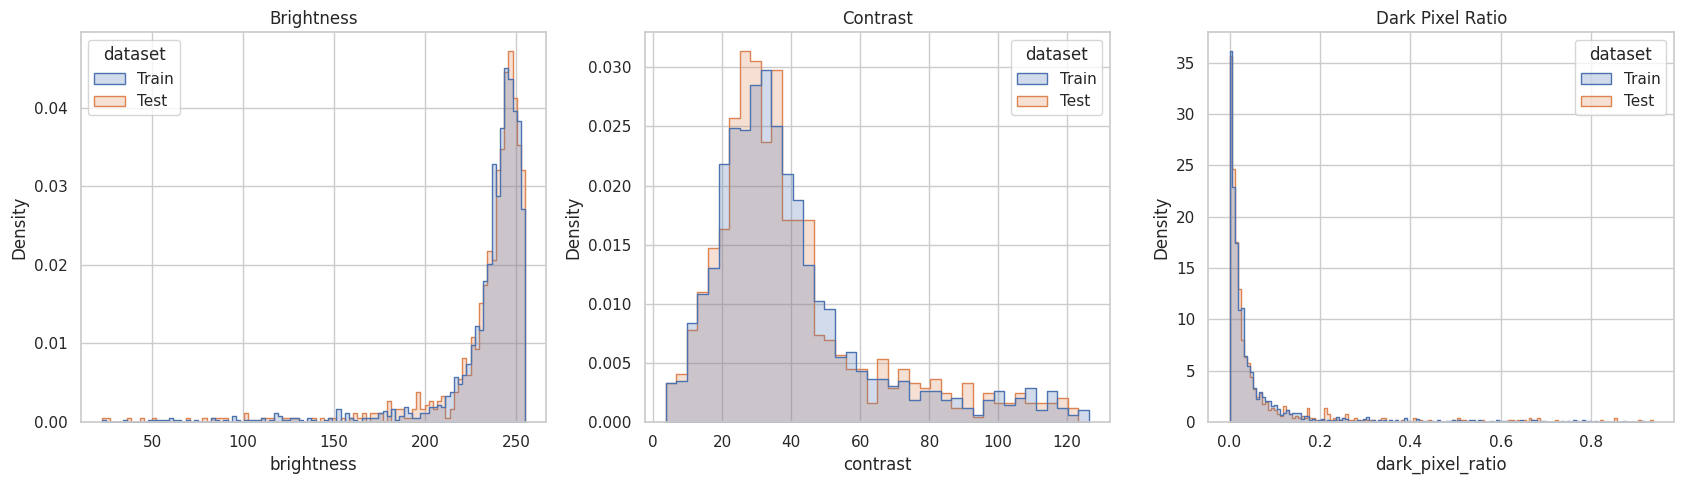

Rata-rata metrik:


,brightness,contrast,dark_pixel_ratio
dataset,,,
Test,233.299,39.741,0.061
Train,233.585,39.624,0.059


In [11]:
# Ambil sampel testing untuk dibandingkan
test_sample = test_df.sample(
    n=min(800, len(test_df)),
    random_state=SEED
)

test_quality_records = []

for _, row in tqdm(
    test_sample.iterrows(),
    total=len(test_sample),
    desc="Analyzing test images"
):
    metrics = calculate_image_quality(
        row["filename"],
        split="test"
    )

    test_quality_records.append({
        "id": row["id"],
        **metrics
    })

test_quality_df = pd.DataFrame(test_quality_records)

train_compare = quality_df.copy()
train_compare["dataset"] = "Train"

test_compare = test_quality_df.copy()
test_compare["dataset"] = "Test"

combined = pd.concat(
    [train_compare, test_compare],
    ignore_index=True
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

columns = [
    "brightness",
    "contrast",
    "dark_pixel_ratio"
]

for ax, column in zip(axes, columns):
    sns.histplot(
        data=combined,
        x=column,
        hue="dataset",
        stat="density",
        common_norm=False,
        element="step",
        ax=ax
    )
    ax.set_title(column.replace("_", " ").title())

plt.tight_layout()
plt.show()

print("Rata-rata metrik:")
display(
    combined.groupby("dataset")[columns]
    .mean()
    .round(3)
)


### 2.7. Deteksi Duplikasi Gambar secara Eksak


In [12]:
import hashlib

def calculate_file_hash(filename):
    """
    Menghitung hash SHA-256 untuk file gambar.

    Args:
        filename (str): Path relatif gambar training.

    Returns:
        str: Hash SHA-256 dari isi file.
    """
    path = resolve_image_path(filename, "train")
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            sha.update(chunk)

    return sha.hexdigest()


hash_records = []

for _, row in tqdm(
    eda_sample.iterrows(),
    total=len(eda_sample),
    desc="Checking exact duplicates"
):
    hash_records.append({
        "id": row["id"],
        "filename": row["filename"],
        "hash": calculate_file_hash(row["filename"])
    })

hash_df = pd.DataFrame(hash_records)

duplicates = hash_df[
    hash_df.duplicated("hash", keep=False)
].sort_values("hash")

print("Jumlah file pada grup duplikat:",
      len(duplicates))

print("Jumlah hash duplikat:",
      duplicates["hash"].nunique())

display(duplicates.head(20))


Checking exact duplicates:   0%|          | 0/1600 [00:00<?, ?it/s]

Jumlah file pada grup duplikat: 0
Jumlah hash duplikat: 0


,id,filename,hash


### 2.8. Ekspor Hasil EDA


In [13]:
EDA_OUTPUT = Path(
    "/kaggle/working/eda_results"
)

EDA_OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

class_dist.to_csv(
    EDA_OUTPUT / "class_distribution.csv",
    index=False
)

stats_df.to_csv(
    EDA_OUTPUT / "image_statistics_sample.csv",
    index=False
)

quality_df.to_csv(
    EDA_OUTPUT / "image_quality_sample.csv",
    index=False
)

test_quality_df.to_csv(
    EDA_OUTPUT / "test_quality_sample.csv",
    index=False
)

hash_df.to_csv(
    EDA_OUTPUT / "sample_file_hashes.csv",
    index=False
)

print("Hasil EDA berhasil disimpan!")
print("Lokasi:", EDA_OUTPUT)

for file in EDA_OUTPUT.iterdir():
    print("-", file.name)


Hasil EDA berhasil disimpan!
Lokasi: /kaggle/working/eda_results
- image_quality_sample.csv
- image_statistics_sample.csv
- class_distribution.csv
- test_quality_sample.csv
- sample_file_hashes.csv
